# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [1]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
kernel: /home/fernando/LunarLander/.venv/bin/python


In [2]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.14.1+cpu | dispositivo: cpu


## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [3]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 1
Estado siguiente: [ 0.004  1.425  0.22   0.295 -0.003 -0.004  0.     0.   ]
Recompensa: 2.080
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [13]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [5]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [12]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.53
Recompensa mediana:  -140.74
Desviación estándar: 112.43
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [7]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


In [8]:
# Implementación del agente DQN
class RedQ(nn.Module):
    """Perceptrón multicapa que aproxima Q(s, ·): recibe el estado (8 dimensiones)
    y devuelve un valor Q por cada acción (4), todo en una sola pasada."""

    def __init__(self, dim_estado, num_acciones, neuronas=(128, 128)):
        super().__init__()
        capas, entrada = [], dim_estado
        for n in neuronas:
            capas += [nn.Linear(entrada, n), nn.ReLU()]
            entrada = n
        capas.append(nn.Linear(entrada, num_acciones))   # salida lineal: Q no está acotado
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)


class BufferReplay:
    """Memoria de experiencias circular, con arreglos preasignados de NumPy.
    Al llenarse, las transiciones nuevas pisan las más viejas."""

    def __init__(self, capacidad, dim_estado):
        self.capacidad = capacidad
        self.estados = np.zeros((capacidad, dim_estado), dtype=np.float32)
        self.acciones = np.zeros(capacidad, dtype=np.int64)
        self.recompensas = np.zeros(capacidad, dtype=np.float32)
        self.siguientes = np.zeros((capacidad, dim_estado), dtype=np.float32)
        self.terminados = np.zeros(capacidad, dtype=np.float32)
        self.pos = 0
        self.tam = 0

    def __len__(self):
        return self.tam

    def agregar(self, estado, accion, recompensa, siguiente, terminado):
        i = self.pos
        self.estados[i], self.acciones[i], self.recompensas[i] = estado, accion, recompensa
        self.siguientes[i], self.terminados[i] = siguiente, float(terminado)
        self.pos = (self.pos + 1) % self.capacidad
        self.tam = min(self.tam + 1, self.capacidad)

    def muestrear(self, tam_lote, rng):
        idx = rng.integers(0, self.tam, size=tam_lote)   # uniforme, con reposición
        return (self.estados[idx], self.acciones[idx], self.recompensas[idx],
                self.siguientes[idx], self.terminados[idx])


class AgenteDQN(Agente):
    """Agente de Red Q Profunda.

    `semilla` fija los generadores (random, NumPy, PyTorch y `accion_space.seed`).
    `elegir_accion(estado, explorar=False)` devuelve la acción greedy, sin explorar.
    `fin_episodio()` se invoca al terminar cada episodio de entrenamiento.

    Interruptores de la ablación (sección 11):
      * `usar_replay=False`: DQN online. No hay buffer: cada transición se usa una
        sola vez, en un lote de tamaño 1, justo cuando ocurre.
      * `usar_target=False`: el objetivo temporal se calcula con la propia red
        online (no existe la red objetivo).
      * ambos en False: Q-learning online con red neuronal, sin ninguna de las dos
        técnicas de estabilización.
    """

    def __init__(self, estado_space, accion_space, semilla=None,
                 tasa_aprendizaje=5e-4, gamma=0.99,
                 epsilon_inicial=1.0, epsilon_final=0.01, decaimiento_epsilon=0.995,
                 tam_buffer=100_000, tam_lote=64, pasos_calentamiento=1_000,
                 frecuencia_entrenamiento=1, frecuencia_target=1_000,
                 neuronas=(128, 128), norma_gradiente=10.0,
                 usar_replay=True, usar_target=True, dispositivo='cpu'):
        self.accion_space = accion_space
        self.dim_estado = int(estado_space.shape[0])
        self.num_acciones = int(accion_space.n)

        # Hiperparámetros (todos configurables para la calibración y la ablación)
        self.tasa_aprendizaje = tasa_aprendizaje
        self.gamma = gamma
        self.epsilon = epsilon_inicial
        self.epsilon_final = epsilon_final
        self.decaimiento_epsilon = decaimiento_epsilon       # multiplicativo, por episodio
        self.tam_lote = tam_lote
        self.pasos_calentamiento = max(pasos_calentamiento, tam_lote)
        self.frecuencia_entrenamiento = frecuencia_entrenamiento   # cada cuántos pasos se actualiza
        self.frecuencia_target = frecuencia_target                 # cada cuántas actualizaciones se copia la red
        self.norma_gradiente = norma_gradiente
        self.usar_replay = usar_replay
        self.usar_target = usar_target
        self.dispositivo = torch.device(dispositivo)

        # Semillas: random, NumPy, PyTorch y el RNG propio del espacio de acciones.
        # Además se usa un Generator local para el sorteo de ε y del minibatch.
        self.semilla = semilla
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)
        self.rng = np.random.default_rng(semilla)

        # Red Q online y (opcional) red objetivo con los mismos pesos iniciales
        self.red_q = RedQ(self.dim_estado, self.num_acciones, neuronas).to(self.dispositivo)
        if usar_target:
            self.red_objetivo = RedQ(self.dim_estado, self.num_acciones, neuronas).to(self.dispositivo)
            self.red_objetivo.load_state_dict(self.red_q.state_dict())
            self.red_objetivo.eval()          # la red objetivo nunca se entrena
        else:
            self.red_objetivo = None
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=tasa_aprendizaje)

        # Memoria de experiencias: solo existe en la variante con replay
        self.buffer = BufferReplay(tam_buffer, self.dim_estado) if usar_replay else None

        # Contadores y trazas para diagnóstico y pruebas
        self.pasos = 0                 # transiciones vistas
        self.actualizaciones = 0       # pasos de gradiente realizados
        self.ultima_perdida = None
        self.ultimo_lote = None        # último lote usado en una actualización

    # Política
    def elegir_accion(self, estado, explorar=True):
        """ε-greedy. Con `explorar=False` devuelve siempre la acción de mayor Q."""

        if explorar and self.rng.random() < self.epsilon:
            return int(self.accion_space.sample())          # acción aleatoria (RNG sembrado)
        with torch.no_grad():                                # sin gradientes al actuar
            s = torch.as_tensor(estado, dtype=torch.float32, device=self.dispositivo).unsqueeze(0)
            return int(self.red_q(s).argmax(dim=1).item())

    # Aprendizaje
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Almacena la experiencia y entrena la red."""

        self.pasos += 1

        if self.usar_replay:
            self.buffer.agregar(estado, accion, recompensa, siguiente_estado, terminado)
            if len(self.buffer) < self.pasos_calentamiento:
                return                                       # calentamiento: solo se acumula
            if self.pasos % self.frecuencia_entrenamiento != 0:
                return
            lote = self.buffer.muestrear(self.tam_lote, self.rng)
        else:
            # Sin replay: se aprende solo de la transición actual (lote de tamaño 1)
            if self.pasos % self.frecuencia_entrenamiento != 0:
                return
            lote = (np.asarray(estado, dtype=np.float32)[None, :],
                    np.asarray([accion], dtype=np.int64),
                    np.asarray([recompensa], dtype=np.float32),
                    np.asarray(siguiente_estado, dtype=np.float32)[None, :],
                    np.asarray([float(terminado)], dtype=np.float32))

        self._actualizar(lote)

    def _calcular_objetivo(self, recompensas, siguientes, terminados):
        """y = r + γ · max_a' Q_objetivo(s', a') · (1 − terminado).

        `terminados` marca solo la terminación real: en los estados terminales el
        valor futuro es 0, pero un episodio truncado por tiempo sí hace bootstrapping.
        Sin red objetivo, el máximo se calcula con la propia red online."""

        red = self.red_objetivo if self.usar_target else self.red_q
        with torch.no_grad():                                # el objetivo no propaga gradiente
            q_siguiente = red(siguientes).max(dim=1).values
        return recompensas + self.gamma * q_siguiente * (1.0 - terminados)

    def _actualizar(self, lote):
        """Un paso de gradiente sobre un lote (estados, acciones, recompensas, siguientes, terminados)."""

        estados, acciones, recompensas, siguientes, terminados = (
            torch.as_tensor(x, device=self.dispositivo) for x in lote)
        self.ultimo_lote = lote

        # Q(s, a) de la acción efectivamente tomada: (B, 4) -> gather -> (B,)
        q_sa = self.red_q(estados).gather(1, acciones.unsqueeze(1)).squeeze(1)
        objetivo = self._calcular_objetivo(recompensas, siguientes, terminados)

        perdida = F.smooth_l1_loss(q_sa, objetivo)           # Huber: robusta a recompensas grandes
        self.optimizador.zero_grad()
        perdida.backward()
        nn.utils.clip_grad_norm_(self.red_q.parameters(), self.norma_gradiente)
        self.optimizador.step()

        self.actualizaciones += 1
        self.ultima_perdida = float(perdida.item())
        if self.usar_target and self.actualizaciones % self.frecuencia_target == 0:
            self.sincronizar_target()

    def sincronizar_target(self):
        """Copia los pesos de la red online en la red objetivo (actualización dura)."""
        if self.red_objetivo is not None:
            self.red_objetivo.load_state_dict(self.red_q.state_dict())

    def fin_episodio(self):
        """El bucle de entrenamiento lo invoca al terminar cada episodio."""
        self.epsilon = max(self.epsilon_final, self.epsilon * self.decaimiento_epsilon)

    # Guardar / cargar
    def guardar(self, ruta):
        """Guarda los pesos de la red Q (y de la objetivo, si existe)."""
        torch.save({'red_q': self.red_q.state_dict(),
                    'red_objetivo': None if self.red_objetivo is None else self.red_objetivo.state_dict(),
                    'epsilon': self.epsilon}, ruta)

    def cargar(self, ruta):
        """Carga pesos guardados con `guardar`."""
        datos = torch.load(ruta, map_location=self.dispositivo)
        self.red_q.load_state_dict(datos['red_q'])
        if self.red_objetivo is not None:
            self.red_objetivo.load_state_dict(datos['red_objetivo'] or datos['red_q'])
        self.epsilon = datos['epsilon']

### Decisiones de diseño del `AgenteDQN`

* **Red Q:** perceptrón multicapa `8 → 128 → 128 → 4` con ReLU y salida lineal. Una sola pasada devuelve el valor Q de las 4 acciones.
* **Objetivo temporal:** `y = r + γ · max_a' Q_objetivo(s', a') · (1 − terminado)`. Solo `terminado` corta el *bootstrapping*, un episodio truncado por tiempo no lo corta (coincide con lo que le pasa `entrenar_agente`).
* **Optimización:** pérdida de Huber (`smooth_l1`), Adam y recorte de la norma del gradiente.
* **Replay:** buffer circular de NumPy con muestreo uniforme y un período de calentamiento antes de empezar a entrenar.
* **Red objetivo:** copia de la red online, actualizada de forma *dura* cada `frecuencia_target` actualizaciones.
* **Exploración:** ε-greedy con decaimiento multiplicativo por episodio (se aplica en `fin_episodio`). Con `explorar=False` el agente es siempre greedy.
* **Reproducibilidad:** `semilla` fija `random`, NumPy, PyTorch y `accion_space.seed`; el sorteo de ε y el muestreo del minibatch usan además un `Generator` propio.
* **Interruptores de la ablación:** `usar_replay=False` (sin buffer, cada transición se usa una sola vez en un lote de tamaño 1) y `usar_target=False` (el objetivo se calcula con la red online). Los hiperparámetros por defecto son solo un punto de partida: la calibración se hace aparte.

Las celdas siguientes son pruebas rápidas de que el agente hace lo que dice (acción, objetivo temporal, actualización y sincronización, variantes, reproducibilidad y guardado).

In [9]:
# Pruebas rápidas (de humo) del AgenteDQN: tardan unos segundos y no entrenan en serio.
import tempfile, os


def _nuevo_agente(**kwargs):
    """Crea un agente con su propio entorno (solo para obtener los espacios)."""

    env = gym.make('LunarLander-v3')
    kwargs.setdefault('semilla', 0)
    return AgenteDQN(env.observation_space, env.action_space, **kwargs)


def _correr_pasos(agente, n_pasos, semilla_env=0):
    """Interactúa `n_pasos` con el entorno y entrena al agente en cada paso."""

    env = gym.make('LunarLander-v3')
    estado, _ = env.reset(seed=semilla_env)
    for _ in range(n_pasos):
        accion = agente.elegir_accion(estado)
        siguiente, recompensa, terminado, truncado, _ = env.step(accion)
        agente.aprender(estado, accion, recompensa, siguiente, terminado)
        estado = siguiente
        if terminado or truncado:
            estado, _ = env.reset()
    env.close()


def _pesos(red):
    """Todos los parámetros de una red, aplanados en un único vector (copia)."""

    return torch.cat([p.detach().flatten() for p in red.parameters()]).clone()


# 1. Elección de acción: greedy determinista y exploración
agente = _nuevo_agente()
estado = np.zeros(8, dtype=np.float32)
greedy = {agente.elegir_accion(estado, explorar=False) for _ in range(50)}
assert len(greedy) == 1 and greedy.pop() in range(4)
agente.epsilon = 1.0
assert len({agente.elegir_accion(estado) for _ in range(300)}) == 4, "con ε=1 deben salir las 4 acciones"
assert len({agente.elegir_accion(estado, explorar=False) for _ in range(50)}) == 1, \
    "con explorar=False debe ser greedy aunque ε=1"
agente.epsilon = 0.0
assert agente.elegir_accion(estado) == agente.elegir_accion(estado, explorar=False)
print("✓ 1. elegir_accion: greedy sin exploración, ε-greedy con exploración")

# 2. Objetivo temporal: terminales, truncados y red objetivo
agente = _nuevo_agente(gamma=0.9)
r = torch.tensor([1.0, 1.0]); sig = torch.randn(2, 8); term = torch.tensor([1.0, 0.0])
y = agente._calcular_objetivo(r, sig, term)
q_max = agente.red_objetivo(sig).max(dim=1).values
assert torch.allclose(y[0], r[0]), "en un estado terminal el objetivo es solo la recompensa"
assert torch.allclose(y[1], r[1] + 0.9 * q_max[1]), "si no es terminal: r + γ·max Q_objetivo(s')"
assert not y.requires_grad, "el objetivo no debe propagar gradiente"
y_antes = agente._calcular_objetivo(r, sig, term)
with torch.no_grad():
    for p in agente.red_q.parameters():
        p.add_(1.0)                                   # se mueve solo la red online
assert torch.allclose(y_antes, agente._calcular_objetivo(r, sig, term)), "la red objetivo está congelada"
print("✓ 2. objetivo temporal: (1 − terminado) correcto, sin gradiente y con red objetivo congelada")

# 3. La red online se actualiza y la objetivo se sincroniza cada N pasos
agente = _nuevo_agente(tam_lote=32, pasos_calentamiento=32, frecuencia_target=20)
inicial = _pesos(agente.red_q)
_correr_pasos(agente, 31)
assert agente.actualizaciones == 0 and torch.equal(_pesos(agente.red_q), inicial), "no se entrena en el calentamiento"
_correr_pasos(agente, 9)
assert agente.actualizaciones == 9 and not torch.equal(_pesos(agente.red_q), inicial), "los pesos online cambian"
assert torch.equal(_pesos(agente.red_objetivo), inicial), "la red objetivo sigue congelada entre sincronizaciones"
_correr_pasos(agente, 11)
assert agente.actualizaciones == 20 and torch.equal(_pesos(agente.red_objetivo), _pesos(agente.red_q)), \
    "tras frecuencia_target actualizaciones, la red objetivo copia a la online"
print("✓ 3. optimización: la red online cambia y la objetivo se sincroniza cada `frecuencia_target`")

# 4. Variante sin replay: solo usa la transición actual
agente = _nuevo_agente(usar_replay=False)
assert agente.buffer is None
env = gym.make('LunarLander-v3'); estado, _ = env.reset(seed=0)
for _ in range(30):
    accion = agente.elegir_accion(estado)
    siguiente, recompensa, terminado, truncado, _ = env.step(accion)
    agente.aprender(estado, accion, recompensa, siguiente, terminado)
    lote = agente.ultimo_lote
    assert lote[0].shape == (1, 8) and np.allclose(lote[0][0], estado) and np.allclose(lote[3][0], siguiente) \
        and lote[1][0] == accion and np.isclose(lote[2][0], recompensa), "el lote debe ser la transición actual"
    estado = siguiente
env.close()
assert agente.actualizaciones == 30, "aprende en cada paso, desde el primero"
agente = _nuevo_agente(tam_lote=32, pasos_calentamiento=32)       # contraste: con replay
_correr_pasos(agente, 100)
assert len(agente.buffer) == 100 and agente.ultimo_lote[0].shape == (32, 8)
print("✓ 4. sin replay: lote de tamaño 1 con la transición actual y sin buffer; con replay: lotes de 32")

# 5. Variante sin red objetivo
agente = _nuevo_agente(usar_target=False)
assert agente.red_objetivo is None
y_antes = agente._calcular_objetivo(r, sig, term)
with torch.no_grad():
    for p in agente.red_q.parameters():
        p.add_(1.0)
assert not torch.allclose(y_antes, agente._calcular_objetivo(r, sig, term)), "el objetivo sigue a la red online"
agente.sincronizar_target()                                        # no debe fallar ni hacer nada
_correr_pasos(agente, 50)
print("✓ 5. sin red objetivo: el objetivo se calcula con la propia red online")

# 6. Reproducibilidad
def _entrenar_corto(semilla):
    agente = _nuevo_agente(semilla=semilla, tam_lote=32, pasos_calentamiento=32)
    _correr_pasos(agente, 150)
    return _pesos(agente.red_q)

assert torch.equal(_entrenar_corto(7), _entrenar_corto(7)), "misma semilla ⇒ mismos pesos"
assert not torch.equal(_entrenar_corto(7), _entrenar_corto(8)), "semillas distintas ⇒ pesos distintos"
print("✓ 6. reproducibilidad: misma semilla da exactamente los mismos pesos")

# 7. Guardar y cargar
agente = _nuevo_agente(semilla=1); _correr_pasos(agente, 40)
otro = _nuevo_agente(semilla=2)
ruta_tmp = os.path.join(tempfile.mkdtemp(), 'dqn_prueba.pt')
agente.guardar(ruta_tmp); otro.cargar(ruta_tmp)
prueba = torch.randn(16, 8)
assert torch.allclose(agente.red_q(prueba), otro.red_q(prueba)), "la red cargada debe dar los mismos Q"
print("✓ 7. guardar/cargar: la red recuperada produce los mismos valores Q")

# 8. Entrenar y evaluar unos episodios en las 4 configuraciones de la ablación
configuraciones = {
    'DQN completo':     dict(usar_replay=True,  usar_target=True),
    'sin replay':       dict(usar_replay=False, usar_target=True),
    'sin red objetivo': dict(usar_replay=True,  usar_target=False),
    'sin ambos':        dict(usar_replay=False, usar_target=False),
}
print(f"\n{'configuración':<18} {'ep. entrenados':>14} {'actualizaciones':>16} {'tam. buffer':>12} {'R eval. (media)':>16}")
for nombre, cfg in configuraciones.items():
    env = gym.make('LunarLander-v3')
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=0,
                       pasos_calentamiento=64, **cfg)
    entrenar_agente(agente, env, num_episodios=3, max_pasos=200, verbose=False, semilla=0)
    res = evaluar_agente(agente, env, num_episodios=2, semilla=10_000)
    env.close()
    tam_buffer = 0 if agente.buffer is None else len(agente.buffer)
    print(f"{nombre:<18} {3:>14} {agente.actualizaciones:>16} {tam_buffer:>12} {res['recompensa_promedio']:>16.1f}")
print("\n✓ 8. las cuatro configuraciones entrenan y evalúan sin excepciones")

✓ 1. elegir_accion: greedy sin exploración, ε-greedy con exploración
✓ 2. objetivo temporal: (1 − terminado) correcto, sin gradiente y con red objetivo congelada
✓ 3. optimización: la red online cambia y la objetivo se sincroniza cada `frecuencia_target`
✓ 4. sin replay: lote de tamaño 1 con la transición actual y sin buffer; con replay: lotes de 32
✓ 5. sin red objetivo: el objetivo se calcula con la propia red online
✓ 6. reproducibilidad: misma semilla da exactamente los mismos pesos
✓ 7. guardar/cargar: la red recuperada produce los mismos valores Q

configuración      ep. entrenados  actualizaciones  tam. buffer  R eval. (media)
Tiempo total de entrenamiento: 1s
DQN completo                    3              204          267           -648.5
Tiempo total de entrenamiento: 1s
sin replay                      3              291            0           -818.7
Tiempo total de entrenamiento: 0s
sin red objetivo                3              204          267           -565.3
Tiempo total 

## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos. Cambiar si lo creen necesario.

**Sobre la parada temprana:** `entrenar_agente` acepta `umbral_resolucion` para
cortar cuando la media móvil de 100 episodios supera un valor.


In [10]:
# Entrenar el agente DQN
env = gym.make('LunarLander-v3')

agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA)

print("\nEntrenando el agente DQN en LunarLander-v3...")
recompensas_episodios, longitudes_episodios = entrenar_agente(
    agente_dqn, env,
    num_episodios=1200,
    max_pasos=1000,
    umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
    semilla=SEMILLA,
    verbose=True,
)

env.close()


Entrenando el agente DQN en LunarLander-v3...
Episodio    60 | Recompensa media (100 ep):  -162.49 | Longitud media:  102.8 | epsilon: 0.740 |    11s
Episodio   120 | Recompensa media (100 ep):   -95.21 | Longitud media:  126.2 | epsilon: 0.548 |    27s
Episodio   180 | Recompensa media (100 ep):   -37.90 | Longitud media:  287.4 | epsilon: 0.406 |    73s
Episodio   240 | Recompensa media (100 ep):     2.21 | Longitud media:  402.8 | epsilon: 0.300 |   117s
Episodio   300 | Recompensa media (100 ep):    69.68 | Longitud media:  519.8 | epsilon: 0.222 |   181s
Episodio   360 | Recompensa media (100 ep):   114.48 | Longitud media:  591.3 | epsilon: 0.165 |   251s
Episodio   420 | Recompensa media (100 ep):   156.38 | Longitud media:  567.8 | epsilon: 0.122 |   331s
Episodio   480 | Recompensa media (100 ep):   170.00 | Longitud media:  467.6 | epsilon: 0.090 |   389s
Episodio   540 | Recompensa media (100 ep):   216.56 | Longitud media:  426.7 | epsilon: 0.067 |   441s
Episodio   600 | 

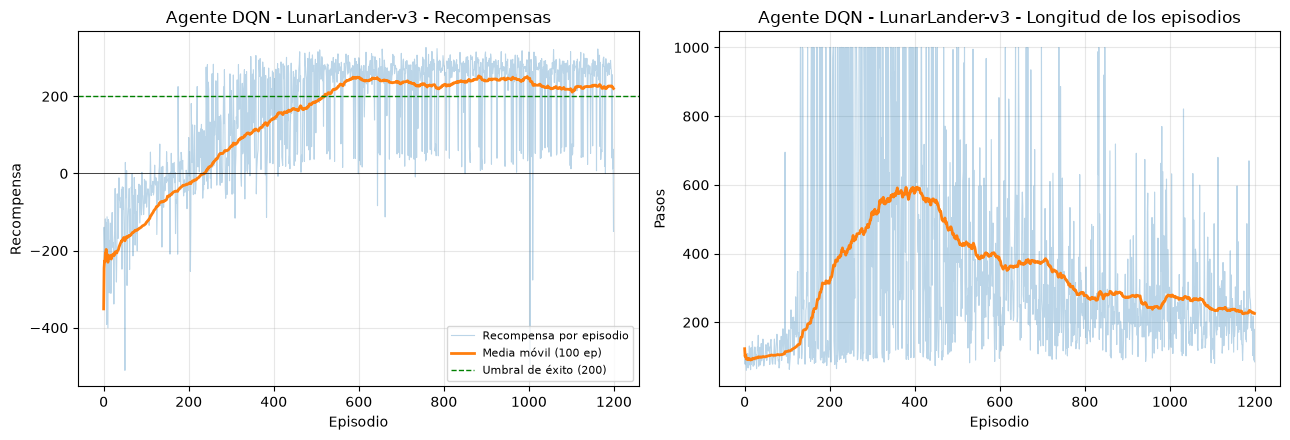

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 220.26
Tasa de éxito (R ≥ 200): 77.0%
Epsilon final: 0.010


In [11]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

In [ ]:
# Guardar los pesos de la red para no reentrenar en otra sesión
agente_dqn.guardar('dqn_lunarlander.pt')

# Para recargar los pesos en el futuro (descomentar cuando sea necesario):
# agente_dqn.cargar('dqn_lunarlander.pt')

## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [ ]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

In [ ]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

In [ ]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


In [ ]:
# TODO 2: cortes de la política
raise NotImplementedError('TODO 2: cortes de la política')


## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


In [ ]:
# TODO 3: estudio de ablación
raise NotImplementedError('TODO 3: estudio de ablación')
